# Part 5:  Vibe-Coding Emerging Optimizers on CIFAR Classification 

As large language models (LLMs) reshape software engineering, we are entering a new era of AI-assisted programming where human creativity and machine execution merge. Instead of focusing on every low-level implementation detail, developers can prioritize **ideas, exploration, and iteration speed**, while the model handles much of the routine coding. This is the essence of [**vibe coding**](https://en.wikipedia.org/wiki/Vibe_coding?utm_source=chatgpt.com): coding by “vibes” and letting AI accelerate the path from concept to working system. In this homework, you will practice vibe coding by using AI assistants such as [ChatGPT](https://chat.openai.com), [Gemini](https://gemini.google.com/app), or [Claude](https://www.anthropic.com/claude-code) to help design and implement optimizers for CIFAR image classification.  

---

## 1. What is *Vibe Coding*? 

**Vibe coding** is a paradigm popularized by Andrej Karpathy in 2025. It emphasizes generating most of the code through LLMs while the human programmer acts as a **guide, tester, and refiner**. Instead of carefully reviewing every line, you iterate based on execution results, keeping the creative process at the center.  

Karpathy put it simply:  
> *“Fully giving in to the vibes, embracing exponentials, and forgetting that the code even exists.”*  

**Learn more :**
- [IBM: What is Vibe Coding?](https://www.ibm.com/think/topics/vibe-coding?utm_source=chatgpt.com)  
- [Replit Blog: What is Vibe Coding?](https://blog.replit.com/what-is-vibe-coding?utm_source=chatgpt.com)  

---

## 2. Objectives 

- Understand and implement **novel optimizers** (Muon, Scion, SODA).  
- Practice **vibe coding** as a workflow with LLMs.  
- Compare optimizer performance on **CIFAR-10** across Transformer and ResNet architectures.  
- Analyze results critically and reflect on the coding process.  

---

## 3. Task Overview 

You will implement and compare four optimizers on **CIFAR-10 classification** with two architectures: a **Transformer**  and a **ResNet** .  

- **Optimizers**: Muon , Scion , SODA , Adam (baseline)  
- **Models**: Transformer, ResNet  
- **Comparison metrics**: convergence speed, final test accuracy , training stability  

---

## 4. Optimizers to Implement 

### (1) Muon 
Muon applies **Newton–Schulz orthonormalization** to gradient updates of 2D weight matrices, making them invariant to input conditioning.  
References:  
- [Muon Blog (Keller Jordan)](https://kellerjordan.github.io/posts/muon/?utm_source=chatgpt.com)  
- [Deriving Muon (Jeremy Bernstein)](https://jeremybernste.in/writing/deriving-muon?utm_source=chatgpt.com)  
- [Muon GitHub Repo](https://github.com/KellerJordan/Muon?utm_source=chatgpt.com)  
- [Convergence Bound (arXiv)](https://arxiv.org/abs/2507.01598?utm_source=chatgpt.com)  

---

### (2) Scion 
Scion constrains updates differently for hidden vs input/output layers, using **spectral norm** for hidden layers and **ℓ∞ norm** for others. This improves stability and hyperparameter transfer.  
References:  
- [Scion Paper](https://arxiv.org/abs/2502.07529)  
- [Scion Official Code](https://github.com/LIONS-EPFL/scion)  

---

### (3) SODA 
SODA wraps a base optimizer with a theoretically grounded, initialization-centered **1/k weight-decay schedule**, motivating us to test whether it improves CIFAR-10 training without tuning weight decay.  
References:  
- [SODA Paper (arXiv)](https://arxiv.org/pdf/2605.11172)  
- [SODA GitHub Repo](https://github.com/tmpethick/soda_code)  

---

### (4) Adam 
Adam is the standard baseline optimizer combining momentum and adaptive learning rates. Use either `Adam` or `AdamW` from PyTorch.

---

## 5. Steps & Deliverables 

1. **Model Implementation (5 pts)**  
   - Build a Transformer for CIFAR classification.  
   - Build a ResNet (ResNet-18 or similar).  

2. **Optimizer Integration (8 pts)**  
   - Implement Muon, Scion, SODA optimizers using your AI assistant in a form which is compatible with `torch.optim.Optimizer`.  
   - Use Adam as baseline.  

3. **Training & Evaluation (7 pts)**  
   - Train both models with all optimizers.  
   - Collect metrics: training loss, validation accuracy, time-to-accuracy.  
   - Present results with plots and a summary table.  

4. **Discussion & Reflection (5 pts)**  
   - Compare optimizers in terms of convergence speed, stability, and accuracy.  
   - Reflect on your experience using **vibe coding** with AI assistants.  
   - What worked well? What challenges did you face?  

---

Good luck and enjoy vibe-coding your way through optimizers!!


## Setup

In [1]:
# Install dependencies if needed:
# %pip install torch torchvision matplotlib numpy

import json
import math
import time
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")


def sync():
    """Wait for queued accelerator work so that wall-clock timings are meaningful."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


print(f"torch {torch.__version__} | device: {device}")

torch 2.11.0 | device: mps


## Model implementation

**Data.** CIFAR-10 has 50,000 training and 10,000 test images (32×32 pixels, 10 classes).

- **Loading:** the images are tiny, so `CifarLoader` keeps the whole dataset on the accelerator as `uint8` and builds every mini-batch there. This takes about 0.3 s per epoch, so the GPU never waits for data the way it would with a CPU `DataLoader`.
- **Augmentation:** each training batch gets a random crop (with 4-pixel zero padding) and a random horizontal flip.
- **Validation:** the official test split is the validation set. It is never used to pick hyperparameters.

**Models** (both trained from scratch with the cross-entropy loss):

- **Transformer** (`CIFARTransformer`, 2.68M parameters): a small Vision Transformer.
  - Input: 4×4 patches give 64 tokens, which a linear patch embedding maps to width 192, plus fixed 2-D sine–cosine position embeddings.
  - Body: 6 pre-norm encoder blocks, each with 3-head self-attention and a GELU MLP of ratio 4.
  - Output: a final LayerNorm, global average pooling over the tokens, then a linear classifier.
- **ResNet-18** (`CIFARResNet`, 11.17M parameters): the CIFAR variant of ResNet-18 (He et al., 2016).
  - Input: a 3×3 stem with no max-pooling.
  - Body: four stages of two BasicBlocks with 64/128/256/512 channels, using BatchNorm.
  - Output: global average pooling, then a linear classifier.

Both models call their first layer `stem` and their classifier `head`. The optimizers below use these names to treat the input and output layers differently from the hidden layers.

In [2]:
CIFAR_MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1)
CIFAR_STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1)


class CifarLoader:
    """CIFAR-10 kept on the accelerator as uint8; mini-batches are augmented and normalized on the fly.

    For 32x32 images this is much faster than a CPU `DataLoader` (no per-image Python work, no host->device
    copies). Training batches use the standard augmentation: random crop with zero padding 4 + horizontal flip.
    """

    def __init__(self, train, batch_size, root="./data", pad=4):
        ds = torchvision.datasets.CIFAR10(root, train=train, download=True)
        self.pad = pad if train else 0
        self.images = F.pad(torch.tensor(ds.data).permute(0, 3, 1, 2), (self.pad,) * 4).to(device)  # (N, 3, H, W) uint8
        self.labels = torch.tensor(ds.targets, device=device)
        self.batch_size, self.train = batch_size, train

    def __len__(self):
        n = len(self.labels) / self.batch_size
        return math.floor(n) if self.train else math.ceil(n)  # drop the last partial batch when training

    def augment(self, x):
        B, width = len(x), x.shape[-1]
        offsets = torch.arange(32, device=device)
        rows = torch.randint(0, 2 * self.pad + 1, (B, 1), device=device) + offsets
        cols = torch.randint(0, 2 * self.pad + 1, (B, 1), device=device) + offsets
        x = x.gather(2, rows[:, None, :, None].expand(B, 3, 32, width)).gather(3, cols[:, None, None, :].expand(B, 3, 32, 32))
        return torch.where(torch.rand(B, 1, 1, 1, device=device) < 0.5, x.flip(3), x)

    def __iter__(self):
        n = len(self.labels)
        order = torch.randperm(n, device=device) if self.train else torch.arange(n, device=device)
        for i in range(len(self)):
            idx = order[i * self.batch_size:(i + 1) * self.batch_size]
            x = self.augment(self.images[idx]) if self.train else self.images[idx]
            yield (x.float() / 255 - CIFAR_MEAN) / CIFAR_STD, self.labels[idx]


BATCH_SIZE = 512
train_loader = CifarLoader(train=True, batch_size=BATCH_SIZE)
test_loader = CifarLoader(train=False, batch_size=1000)
print(f"train: {len(train_loader.labels)} images, {len(train_loader)} steps/epoch | test: {len(test_loader.labels)} images")

train: 50000 images, 97 steps/epoch | test: 10000 images


In [3]:
def sincos_pos_embedding(h, w, dim, temperature=10000.0):
    """Fixed 2-D sine-cosine position embeddings (as in "Better plain ViT baselines", Beyer et al., 2022)."""
    y, x = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    omega = temperature ** -(torch.arange(dim // 4) / (dim // 4 - 1))
    y, x = y.flatten()[:, None] * omega, x.flatten()[:, None] * omega
    return torch.cat([x.sin(), x.cos(), y.sin(), y.cos()], dim=1)


class TransformerBlock(nn.Module):
    """Pre-norm transformer encoder block: multi-head self-attention followed by a GELU MLP."""

    def __init__(self, dim, heads, mlp_ratio):
        super().__init__()
        self.heads = heads
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.qkv, self.proj = nn.Linear(dim, 3 * dim), nn.Linear(dim, dim)
        self.fc1, self.fc2 = nn.Linear(dim, mlp_ratio * dim), nn.Linear(mlp_ratio * dim, dim)

    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(self.norm1(x)).view(B, N, 3, self.heads, D // self.heads).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, N, D))
        return x + self.fc2(F.gelu(self.fc1(self.norm2(x))))


class CIFARTransformer(nn.Module):
    """Small Vision Transformer: 4x4 patches -> 64 tokens, 6 pre-norm blocks, global average pooling."""

    def __init__(self, dim=192, depth=6, heads=3, mlp_ratio=4, patch=4, num_classes=10):
        super().__init__()
        self.patch = patch
        self.stem = nn.Linear(3 * patch * patch, dim)  # patch embedding (input layer)
        self.register_buffer("pos_embed", sincos_pos_embedding(32 // patch, 32 // patch, dim))
        self.blocks = nn.Sequential(*[TransformerBlock(dim, heads, mlp_ratio) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)  # classifier (output layer)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        p = self.patch
        x = x.unfold(2, p, p).unfold(3, p, p).permute(0, 2, 3, 1, 4, 5).flatten(3).flatten(1, 2)  # (B, 64, 3*p*p)
        x = self.blocks(self.stem(x) + self.pos_embed)
        return self.head(self.norm(x).mean(dim=1))

In [4]:
class BasicBlock(nn.Module):
    """Two 3x3 conv-BN layers with an identity (or 1x1 conv) shortcut, as in He et al. (2016)."""

    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.shortcut = nn.Sequential()
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)) + self.shortcut(x))


class CIFARResNet(nn.Module):
    """ResNet-18 for 32x32 inputs (3x3 stem, no max-pool), widths 64-128-256-512."""

    def __init__(self, num_classes=10, width=64, blocks=(2, 2, 2, 2)):
        super().__init__()
        self.stem = nn.Conv2d(3, width, 3, 1, 1, bias=False)  # input layer
        self.stem_bn = nn.BatchNorm2d(width)
        layers, c_in = [], width
        for i, n in enumerate(blocks):
            for j in range(n):
                layers.append(BasicBlock(c_in, width * 2**i, stride=2 if i > 0 and j == 0 else 1))
                c_in = width * 2**i
        self.layers = nn.Sequential(*layers)
        self.head = nn.Linear(c_in, num_classes)  # classifier (output layer)

    def forward(self, x):
        x = self.layers(F.relu(self.stem_bn(self.stem(x))))
        return self.head(F.adaptive_avg_pool2d(x, 1).flatten(1))

## Optimizer integration

All four optimizers subclass `torch.optim.Optimizer`, so they work with standard tools such as `torch.optim.lr_scheduler`. Each port was checked numerically against the authors' code:

- Muon's hidden-layer update matches Keller Jordan's `muon_update`.
- Muon's auxiliary Adam matches `torch.optim.AdamW`.
- Scion's constrained step matches its update formula.
- SODA's wrapper matches Algorithm 1 of the paper.

`param_roles` splits each model into the parameter roles that the new optimizers treat differently:

| Parameter role | AdamW | Muon | Scion | SODA(Muon) |
|---|---|---|---|---|
| input layer (`stem`: conv / patch embedding) | AdamW | AdamW | spectral LMO | wrapped Muon |
| hidden weight matrices and conv filters | AdamW | orthogonalized Nesterov momentum | spectral LMO | wrapped Muon |
| output layer (`head`) | AdamW | AdamW | sign ($\ell_\infty$) LMO | wrapped Muon |
| biases, BatchNorm/LayerNorm gains | AdamW (no decay) | AdamW | RMS-normalized LMO | wrapped Muon |
| weight decay | decoupled, 0.05 | decoupled, 0.01 | implicit: $x \leftarrow (1-\gamma)x - \gamma\rho\,\mathrm{lmo}(d)$ | none in the base; $\tfrac{1}{k+2}$ decay towards $x^0$ |

**Muon** (Jordan et al., 2024) is a single-device port of `MuonWithAuxAdam`.
- *Hidden layers:* the Nesterov momentum $m$ is replaced by its approximate orthogonal factor $UV^\top$ (where $m=USV^\top$), computed with 5 quintic Newton–Schulz iterations. Conv filters are first reshaped to out × in·k².
- *Hidden-layer settings:* lr 0.02, momentum 0.95, decoupled weight decay 0.01.
- *Other parameters:* the input and output layers and all vectors use AdamW (lr $10^{-3}$, $\beta=(0.9, 0.95)$), as the authors recommend.
- *Precision:* the Newton–Schulz iteration runs in bf16 on CUDA, as in the reference. On Apple MPS fp32 was faster (8.6 ms vs. 14.6 ms for a 512×4608 matrix), so fp32 is used there.

**Scion** (Pethick et al., 2025) is a stochastic conditional-gradient method with a separate norm constraint for each layer.
- *Update:* each layer moves along the linear minimization oracle (LMO) of its norm ball, applied to the momentum $d \leftarrow (1-\alpha)d + \alpha g$.
- *Norms:* the spectral (RMS→RMS operator) norm for the input and hidden layers, the $\ell_\infty$-type sign LMO for the classifier, and RMS normalization for biases and gains.
- *Variant:* the default constrained version, which keeps every layer inside a ball of radius $\rho$.

**SODA** (Pethick et al., 2026) is the wrapper from the paper's Algorithm 1, placed around the same Muon with its weight decay set to 0.
- *Update:* after every base step it applies $x^{k+1}=\mathrm{BaseStep}(x^k)+\tfrac{1}{k+2}(x^0-x^k)$. This is a parameter-free $1/k$ weight-decay schedule centred at the initialization.
- *Tuning:* nothing is re-tuned, so Muon vs. SODA(Muon) isolates the effect of replacing a hand-picked weight decay by SODA's schedule.

**AdamW** is the baseline: lr $10^{-3}$, $\beta=(0.9,0.999)$, weight decay 0.05 on weight matrices only.

**Hyperparameter selection.** Muon keeps its widely used defaults. If anything, this understates Muon and SODA(Muon), which shares them. Scion's published configurations are architecture-specific, and both transferred poorly to these models:
- *ResNet-18:* the airbench CNN config (head scale 128, bias/gain radius 8) assumes frozen BatchNorm gains and logits scaled by 1/9. With it, training loss rose from 2.34 to 2.64 over the first 30 steps.
- *Transformer:* the nanoGPT config moves the LayerNorm gains and biases by $\gamma\rho \approx 0.012$ per entry and step, about ten times Adam's $\approx 10^{-3}$.

I therefore ran a short pilot: 2 epochs, with the same warm-up and decay schedule compressed into them. I selected the configuration with the lowest **training loss**, so the validation split was not used. For Scion, the decisive fix in both models was a small radius for biases and gains ($\rho_{\text{vec}}=1$); its learning rate was then bracketed. To keep the baseline fair, AdamW's learning rate was bracketed with the same protocol (second table).
- *Transformer:* the bracket confirmed the default $10^{-3}$.
- *ResNet-18:* the pilot slightly preferred $5\cdot10^{-4}$ (0.956 vs. 0.977). A full 10-epoch run with $5\cdot10^{-4}$, however, ended at a *higher* training loss than the default (0.256 vs. 0.228; accuracy 87.6% vs. 89.2%), so the default is kept.

Two-epoch pilots are therefore only good for catching coarse problems, such as Scion's mis-scaled defaults, not for fine-tuning.

| Model | lr $\gamma$ | $\rho_{\text{vec}}$ | head scale | pilot train loss |
|---|---|---|---|---|
| ResNet-18 ($\rho=8$, $\alpha=0.5$) | $2^{-4}$ | 8 | 128 (official) | 1.897 |
| | $2^{-4}$ / $2^{-4}$ / $2^{-5}$ | 8 / 1 / 1 | 16 | 1.488 / 1.053 / 0.671 |
| | **$2^{-6}$** / $2^{-7}$ | 1 | 16 | **0.574** / 0.663 |
| Transformer ($\rho=50$, $\alpha=0.1$) | $2^{-12}$ (official) / $2^{-10}$ | 50 | 3000 | 1.481 / 1.848 |
| | $2^{-12}$ / **$2^{-11}$** / $2^{-10}$ | 1 | 3000 | 1.273 / **1.111** / 1.183 |
| | $2^{-10}$ / $2^{-9}$ | 1 | 300 | 1.195 / 1.435 |

| AdamW lr | $2.5\cdot10^{-4}$ | $5\cdot10^{-4}$ | $10^{-3}$ | $2\cdot10^{-3}$ | $4\cdot10^{-3}$ |
|---|---|---|---|---|---|
| ResNet-18: pilot train loss | 1.010 | **0.956** | 0.977 | 1.112 | 1.358 |
| Transformer: pilot train loss | – | 1.743 | **1.693** | 1.785 | 2.145 |

In [5]:
def param_roles(model):
    """Split parameters by role: input layer, hidden weight matrices/filters, output layer, vectors (biases, gains)."""
    first, last = model.stem.weight, model.head.weight
    rest = [p for p in model.parameters() if p is not first and p is not last]
    return dict(input=[first], hidden=[p for p in rest if p.ndim >= 2], output=[last], vector=[p for p in rest if p.ndim < 2])


def zeropower_via_newtonschulz5(G, steps=5):
    """Approximate the orthogonal factor U V^T of G = U S V^T with Muon's quintic Newton-Schulz iteration."""
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.bfloat16() if G.is_cuda else G.float()  # bf16 only pays off on CUDA; on Apple MPS fp32 is faster
    if G.size(-2) > G.size(-1):
        X = X.mT
    X = X / (X.norm(dim=(-2, -1), keepdim=True) + 1e-7)  # ensure spectral norm <= 1
    for _ in range(steps):
        A = X @ X.mT
        X = a * X + (b * A + c * A @ A) @ X
    if G.size(-2) > G.size(-1):
        X = X.mT
    return X.to(G.dtype)


class Muon(torch.optim.Optimizer):
    """Muon (Jordan et al., 2024): Nesterov SGD-momentum whose update is orthogonalized by Newton-Schulz.

    Single-device version of `MuonWithAuxAdam` (github.com/KellerJordan/Muon). Groups with `use_muon=True`
    (hidden matrices; conv filters are viewed as out x (in*k*k)) receive the Muon update; the other groups
    (input layer, output layer, biases and gains) are trained with AdamW, as recommended by the authors.
    """

    def __init__(self, param_groups):
        for group in param_groups:
            defaults = (dict(lr=0.02, momentum=0.95, nesterov=True, ns_steps=5, weight_decay=0.0) if group["use_muon"]
                        else dict(lr=3e-4, betas=(0.9, 0.95), eps=1e-10, weight_decay=0.0))
            for key, value in defaults.items():
                group.setdefault(key, value)
        super().__init__(param_groups, {})

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                g, state = p.grad, self.state[p]
                p.mul_(1 - group["lr"] * group["weight_decay"])  # decoupled weight decay
                if group["use_muon"]:
                    if "momentum_buffer" not in state:
                        state["momentum_buffer"] = torch.zeros_like(p)
                    buf = state["momentum_buffer"].lerp_(g, 1 - group["momentum"])
                    update = g.lerp(buf, group["momentum"]) if group["nesterov"] else buf
                    update = zeropower_via_newtonschulz5(update.reshape(len(p), -1), group["ns_steps"])
                    update *= max(1, update.size(-2) / update.size(-1)) ** 0.5
                    p.add_(update.reshape(p.shape), alpha=-group["lr"])
                else:
                    if "exp_avg" not in state:
                        state.update(step=0, exp_avg=torch.zeros_like(p), exp_avg_sq=torch.zeros_like(p))
                    state["step"] += 1
                    beta1, beta2 = group["betas"]
                    state["exp_avg"].lerp_(g, 1 - beta1)
                    state["exp_avg_sq"].lerp_(g.square(), 1 - beta2)
                    denom = (state["exp_avg_sq"] / (1 - beta2 ** state["step"])).sqrt_().add_(group["eps"])
                    p.addcdiv_(state["exp_avg"], denom, value=-group["lr"] / (1 - beta1 ** state["step"]))
        return loss


def make_muon(model, lr=0.02, adam_lr=1e-3, weight_decay=0.01):
    roles = param_roles(model)
    return Muon([
        dict(params=roles["hidden"], use_muon=True, lr=lr, momentum=0.95, weight_decay=weight_decay),
        dict(params=roles["input"] + roles["output"] + roles["vector"], use_muon=False, lr=adam_lr,
             betas=(0.9, 0.95), weight_decay=weight_decay),
    ])

In [6]:
def spectral_lmo(g):
    """Hidden/input matrices: unit ball of the RMS->RMS operator norm (spectral norm scaled by sqrt(d_in/d_out))."""
    return zeropower_via_newtonschulz5(g) * (g.size(0) / g.size(1)) ** 0.5


def spectral_conv_lmo(g):
    """Conv filters (out, in, k, k): spectral LMO of the out x (in*k*k) matrix, rescaled as in the Scion code."""
    out_ch, in_ch, k, _ = g.shape
    return zeropower_via_newtonschulz5(g.reshape(out_ch, -1)).reshape(g.shape) * (out_ch / in_ch) ** 0.5 / k**2


def sign_lmo(g):
    """Output layer: l_inf-type ball (sign of the gradient), normalized by the fan-in."""
    return torch.sign(g) / g.size(1)


def bias_rms_lmo(g):
    """Biases and normalization gains: RMS-normalized direction."""
    return g / (g.square().mean().sqrt() + 1e-8)


def auto_lmo(g):
    return spectral_conv_lmo(g) if g.ndim == 4 else spectral_lmo(g) if g.ndim == 2 else bias_rms_lmo(g)


SCION_LMOS = dict(Spectral=spectral_lmo, SpectralConv=spectral_conv_lmo, Sign=sign_lmo, BiasRMS=bias_rms_lmo, Auto=auto_lmo)


class Scion(torch.optim.Optimizer):
    """Scion (Pethick et al., 2025): stochastic conditional gradient with layer-wise norm-ball LMOs.

    Port of github.com/LIONS-EPFL/scion. Every group chooses a norm through its linear minimization oracle
    (spectral for hidden layers, sign/l_inf for the output layer, RMS for biases and gains). `momentum`
    follows the paper's convention d <- (1 - momentum) d + momentum * g (one minus the usual momentum).
    With `unconstrained=False`, x <- (1 - lr) x - lr * scale * lmo(d) keeps each layer in a ball of radius `scale`.
    """

    def __init__(self, params, lr=1e-3, momentum=1.0, norm="Auto", scale=1.0, unconstrained=False):
        super().__init__(params, dict(lr=lr, momentum=momentum, norm=norm, scale=scale, unconstrained=unconstrained))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lmo = SCION_LMOS[group["norm"]]
            for p in group["params"]:
                if p.grad is None:
                    continue
                d = p.grad
                if group["momentum"] != 1:
                    if "momentum_buffer" not in self.state[p]:
                        self.state[p]["momentum_buffer"] = torch.zeros_like(p)
                    d = self.state[p]["momentum_buffer"].lerp_(d, group["momentum"])
                if not group["unconstrained"]:
                    p.mul_(1 - group["lr"])
                p.add_(lmo(d), alpha=-group["lr"] * group["scale"])
        return loss


# Starting points: the official airbench (CNN) and nanoGPT (transformer) configurations; lr, vector_scale and
# head_scale were then chosen by *training* loss in a short 2-epoch pilot (see the table above).
SCION_HPARAMS = {
    "CIFARResNet": dict(lr=2**-6, momentum=0.5, radius=8.0, vector_scale=1.0, head_scale=16.0),
    "CIFARTransformer": dict(lr=2**-11, momentum=0.1, radius=50.0, vector_scale=1.0, head_scale=3000.0),
}


def make_scion(model):
    hp, roles = SCION_HPARAMS[type(model).__name__], param_roles(model)
    return Scion([
        dict(params=roles["input"] + roles["hidden"], norm="Auto", scale=hp["radius"]),
        dict(params=roles["vector"], norm="BiasRMS", scale=hp["vector_scale"]),
        dict(params=roles["output"], norm="Sign", scale=hp["head_scale"]),
    ], lr=hp["lr"], momentum=hp["momentum"])

In [7]:
class SODA(torch.optim.Optimizer):
    """SODA wrapper (Pethick et al., 2026, Algorithm 1) around any base optimizer *without* weight decay:

        x_{k+1} = BaseStep(x_k) + (z_0 - x_k) / (k + 2),

    i.e. weight decay with the parameter-free schedule 1/(k+2), centered at the initialization z_0
    (equivalently, uniform averaging of dual-averaging iterates). Port of `SODAWrapper` (github.com/tmpethick/soda_code).
    """

    def __init__(self, base):
        self.base = base
        for group in base.param_groups:
            group.setdefault("k", 0)

    param_groups = property(lambda self: self.base.param_groups)
    state = property(lambda self: self.base.state)

    def zero_grad(self, set_to_none=True):
        self.base.zero_grad(set_to_none)

    def state_dict(self):
        return self.base.state_dict()

    def load_state_dict(self, state_dict):
        self.base.load_state_dict(state_dict)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        prev = {p: p.clone() for group in self.param_groups for p in group["params"] if p.grad is not None}
        self.base.step()
        for group in self.param_groups:
            for p in group["params"]:
                if p in prev:
                    z0 = self.state[p].setdefault("z0", prev[p])  # anchor: the initialization
                    p.add_(z0 - prev[p], alpha=1 / (group["k"] + 2))
            group["k"] += 1
        return loss


def make_soda(model):
    return SODA(make_muon(model, weight_decay=0.0))  # base optimizer: Muon (+ AdamW for non-hidden layers)

In [8]:
def make_adamw(model, lr=1e-3, weight_decay=0.05):
    roles = param_roles(model)
    return torch.optim.AdamW([
        dict(params=roles["input"] + roles["hidden"] + roles["output"], weight_decay=weight_decay),
        dict(params=roles["vector"], weight_decay=0.0),  # no decay on biases and normalization gains
    ], lr=lr, betas=(0.9, 0.999))

## Training and evaluation

**Protocol.** All (model, optimizer) pairs share the same budget and pipeline:

- **Training:** from scratch for 10 epochs at batch size 512, which gives 970 steps.
- **Learning-rate schedule:** the same for every optimizer, multiplying each parameter group's base learning rate. It warms up linearly over the first 5% of the steps and then decays linearly to 0.
- **Seed:** one fixed seed, so every run starts from the same initialization and sees the same sequence of augmented batches.

**Metrics recorded:**

- training loss at every step;
- validation loss and accuracy after every epoch;
- wall-clock time of the training loop, with evaluation excluded and the accelerator synchronized;
- *time-to-accuracy*: the training time at which validation accuracy first reaches 85% (ResNet-18) or 65% (Transformer);
- *stability*: the largest epoch-to-epoch drop of validation accuracy, together with the raw per-step loss curves.

The runs were done on an Apple M4 Pro GPU through PyTorch's MPS backend. Absolute times depend on the machine and its power mode, so only the relative comparison between optimizers matters.

In [9]:
EPOCHS = 10
WARMUP_FRAC = 0.05  # linear warm-up over the first 5% of the steps, then linear decay to zero (same for all optimizers)


def evaluate(model, loader):
    model.eval()
    loss = correct = 0.0
    with torch.no_grad():
        for x, y in loader:
            logits = model(x)
            loss += F.cross_entropy(logits, y, reduction="sum")
            correct += (logits.argmax(1) == y).sum()
    return loss.item() / len(loader.labels), correct.item() / len(loader.labels)


def epoch_log(label, hist, epoch, epochs):
    return (f"{label} epoch {epoch + 1:2d}/{epochs} | train loss {hist['train_loss'][epoch]:.4f} | val loss {hist['val_loss'][epoch]:.4f} "
            f"| val acc {100 * hist['val_acc'][epoch]:5.2f}% | {hist['epoch_time'][epoch]:5.1f}s")


def train_and_evaluate(model_fn, optimizer_fn, epochs=EPOCHS, seed=0, label="", stop_after=None, callback=None):
    """Train from scratch and evaluate on the held-out test split after every epoch.

    The seed fixes the initialization and the data order, so all optimizers see exactly the same batches.
    Only the training loop is timed (evaluation is excluded from the wall-clock budget).
    `stop_after` trains only the first epochs of the `epochs`-long schedule; `callback(model, epoch)` runs after each epoch.
    """
    torch.manual_seed(seed)
    model = model_fn().to(device)
    optimizer = optimizer_fn(model)
    total = epochs * len(train_loader)
    warmup = max(1, int(WARMUP_FRAC * total))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min((s + 1) / warmup, (total - s) / (total - warmup)))
    hist = dict(step_loss=[], train_loss=[], val_loss=[], val_acc=[], epoch_time=[])
    for epoch in range(stop_after or epochs):
        model.train()
        losses = []
        sync()
        start = time.perf_counter()
        for x, y in train_loader:
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            losses.append(loss.detach())
        sync()
        hist["epoch_time"].append(time.perf_counter() - start)
        hist["step_loss"] += torch.stack(losses).tolist()
        hist["train_loss"].append(float(np.mean(hist["step_loss"][-len(losses):])))
        val_loss, val_acc = evaluate(model, test_loader)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        print(epoch_log(label, hist, epoch, epochs), flush=True)
        if callback is not None:
            callback(model, epoch)
        if not math.isfinite(hist["train_loss"][-1]):
            print(f"{label} diverged, stopping this run")
            break
    return hist

In [10]:
MODELS = {"ResNet-18": CIFARResNet, "Transformer": CIFARTransformer}
OPTIMIZERS = {"AdamW": make_adamw, "Muon": make_muon, "Scion": make_scion, "SODA(Muon)": make_soda}

for name, model_fn in MODELS.items():
    print(f"{name}: {sum(p.numel() for p in model_fn().parameters()) / 1e6:.2f}M parameters")

# Finished runs are cached so that the plots can be regenerated without retraining (delete the file to retrain).
RESULTS_FILE = Path(f"part5_results_{EPOCHS}ep.json")
results = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.exists() else {}
for model_name, model_fn in MODELS.items():
    for opt_name, opt_fn in OPTIMIZERS.items():
        label = f"{model_name} | {opt_name:10s} |"
        if opt_name in results.setdefault(model_name, {}):
            h = results[model_name][opt_name]
            print(f"{label} loaded from {RESULTS_FILE}:")
            for epoch in range(len(h["val_acc"])):
                print(epoch_log(label, h, epoch, len(h["val_acc"])))
            continue
        results[model_name][opt_name] = train_and_evaluate(model_fn, opt_fn, label=label)
        RESULTS_FILE.write_text(json.dumps(results))

ResNet-18: 11.17M parameters
Transformer: 2.68M parameters


ResNet-18 | AdamW      | epoch  1/10 | train loss 1.4894 | val loss 1.3312 | val acc 54.11% |  44.9s


ResNet-18 | AdamW      | epoch  2/10 | train loss 0.9321 | val loss 0.9820 | val acc 67.13% |  45.4s


ResNet-18 | AdamW      | epoch  3/10 | train loss 0.7042 | val loss 1.2876 | val acc 62.96% |  45.4s


ResNet-18 | AdamW      | epoch  4/10 | train loss 0.5812 | val loss 0.7927 | val acc 74.59% |  45.4s


...

ResNet-18 | AdamW      | epoch  7/10 | train loss 0.3676 | val loss 0.4747 | val acc 84.23% |  45.4s


ResNet-18 | AdamW      | epoch  8/10 | train loss 0.3171 | val loss 0.4445 | val acc 85.44% |  45.1s


ResNet-18 | AdamW      | epoch  9/10 | train loss 0.2708 | val loss 0.3817 | val acc 87.51% |  45.1s


ResNet-18 | AdamW      | epoch 10/10 | train loss 0.2284 | val loss 0.3311 | val acc 89.17% |  45.3s


ResNet-18 | Muon       | loaded from part5_results_10ep.json:
ResNet-18 | Muon       | epoch  1/10 | train loss 1.3659 | val loss 1.2766 | val acc 61.98% |  48.7s
ResNet-18 | Muon       | epoch  2/10 | train loss 0.6289 | val loss 0.6322 | val acc 78.77% |  48.2s
ResNet-18 | Muon       | epoch  3/10 | train loss 0.4398 | val loss 0.5089 | val acc 83.16% |  47.6s
ResNet-18 | Muon       | epoch  4/10 | train loss 0.3359 | val loss 0.4442 | val acc 85.04% |  47.8s
ResNet-18 | Muon       | epoch  5/10 | train loss 0.2596 | val loss 0.3381 | val acc 88.67% |  47.6s
ResNet-18 | Muon       | epoch  6/10 | train loss 0.1992 | val loss 0.3399 | val acc 88.98% |  47.9s
ResNet-18 | Muon       | epoch  7/10 | train loss 0.1520 | val loss 0.2879 | val acc 90.71% |  47.6s
ResNet-18 | Muon       | epoch  8/10 | train loss 0.1137 | val loss 0.2886 | val acc 90.94% |  47.7s
ResNet-18 | Muon       | epoch  9/10 | train loss 0.0812 | val loss 0.2709 | val acc 91.71% |  47.9s
ResNet-18 | Muon       | epoc

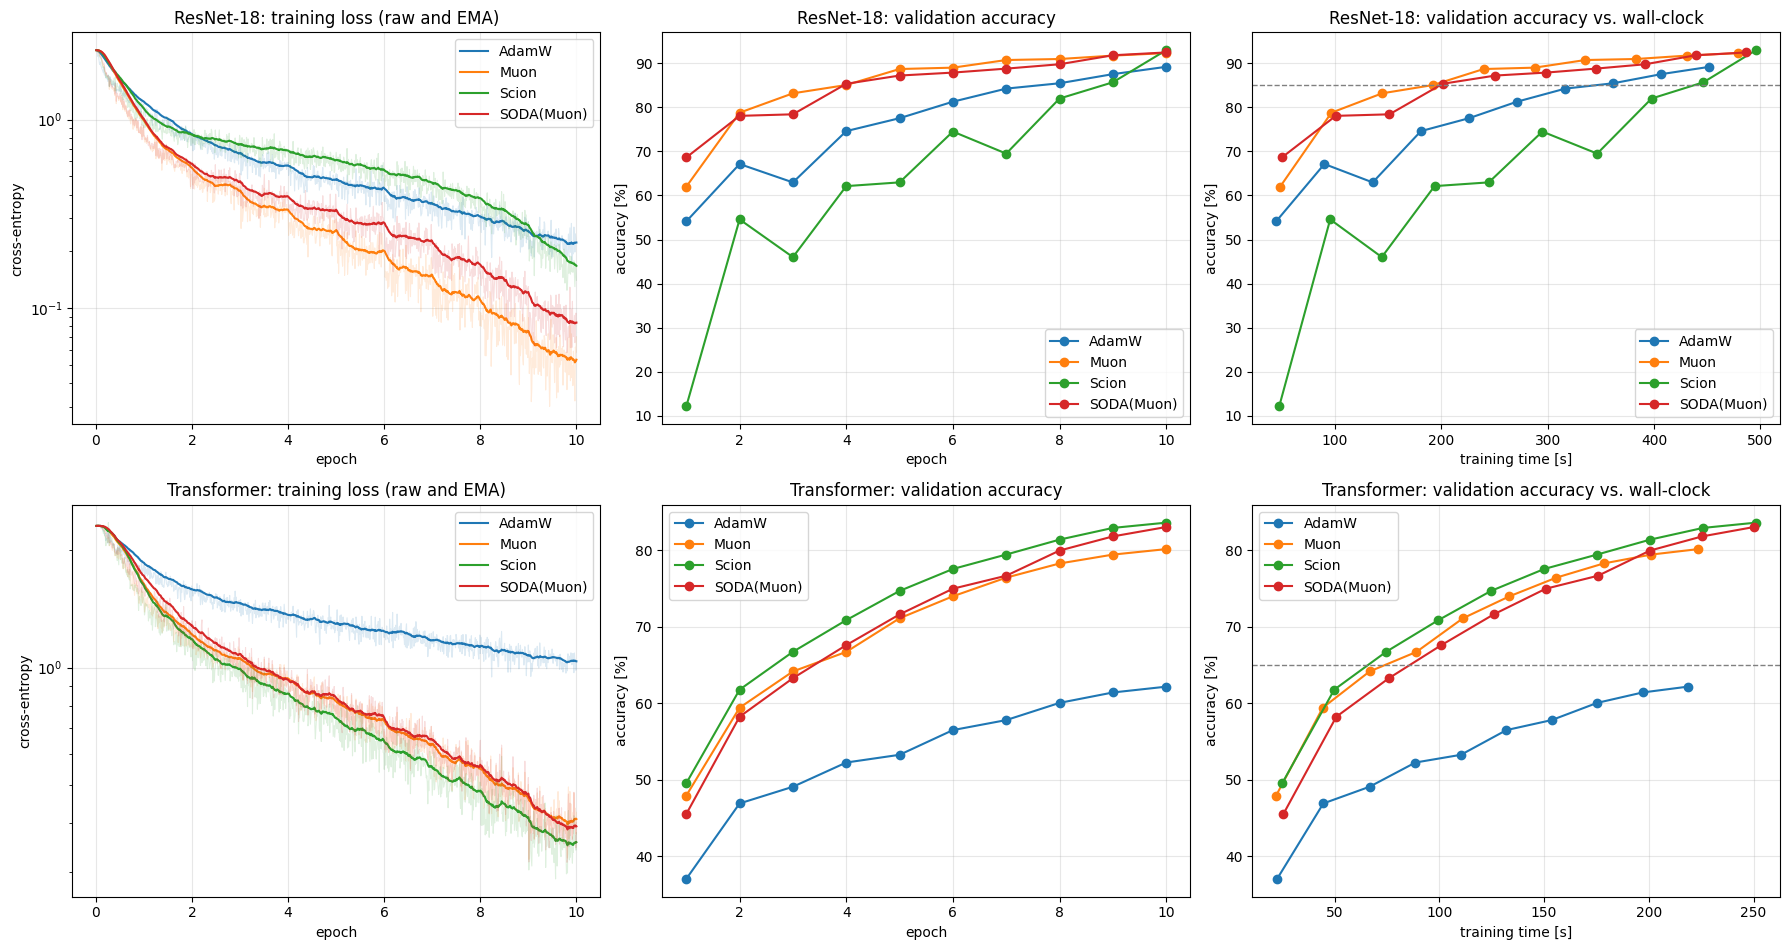

| Model | Optimizer | Final val acc (%) | Best val acc (%) | Final train loss | Final val loss | Time / epoch (s) | Total train time (s) | Time to target acc | Largest val-acc drop (pp) |
|---|---|---|---|---|---|---|---|---|---|
| ResNet-18 | AdamW | 89.17 | 89.17 | 0.2284 | 0.3311 | 45.2 | 452 | 362 s (epoch 8) | 4.17 |
| ResNet-18 | Muon | 92.28 | 92.28 | 0.0548 | 0.2584 | 47.9 | 479 | 192 s (epoch 4) | 0.00 |
| ResNet-18 | Scion | 92.95 | 92.95 | 0.1895 | 0.2127 | 49.6 | 496 | 446 s (epoch 9) | 8.55 |
| ResNet-18 | SODA(Muon) | 92.43 | 92.43 | 0.0876 | 0.2341 | 48.7 | 487 | 201 s (epoch 4) | 0.00 |
| Transformer | AdamW | 62.18 | 62.18 | 1.0475 | 1.0523 | 21.9 | 219 | not reached | 0.00 |
| Transformer | Muon | 80.17 | 80.17 | 0.4094 | 0.5761 | 22.4 | 224 | 89 s (epoch 4) | 0.00 |
| Transformer | Scion | 83.63 | 83.63 | 0.3616 | 0.4946 | 25.1 | 251 | 75 s (epoch 3) | 0.00 |
| Transformer | SODA(Muon) | 83.06 | 83.06 | 0.3989 | 0.4967 | 25.0 | 250 | 101 s (epoch 4) | 0.00 |

Target accuracy: ResNet-18 85%, Transformer 65%

In [11]:
TARGET_ACC = {"ResNet-18": 0.85, "Transformer": 0.65}  # thresholds for the time-to-accuracy metric
COLORS = dict(zip(OPTIMIZERS, plt.cm.tab10.colors))


def ema(values, beta=0.95):
    out, m = [], values[0]
    for v in values:
        m = beta * m + (1 - beta) * v
        out.append(m)
    return np.array(out)


fig, axes = plt.subplots(len(MODELS), 3, figsize=(18, 4.8 * len(MODELS)))
for row, model_name in zip(axes, MODELS):
    for opt_name in OPTIMIZERS:
        h = results[model_name][opt_name]
        color, acc = COLORS[opt_name], 100 * np.array(h["val_acc"])
        epoch_axis = np.arange(1, len(h["step_loss"]) + 1) / (len(h["step_loss"]) / len(acc))
        row[0].plot(epoch_axis, h["step_loss"], color=color, alpha=0.15, lw=0.8)
        row[0].plot(epoch_axis, ema(h["step_loss"]), color=color, label=opt_name)
        row[1].plot(np.arange(1, len(acc) + 1), acc, "o-", color=color, label=opt_name)
        row[2].plot(np.cumsum(h["epoch_time"]), acc, "o-", color=color, label=opt_name)
    row[0].set(title=f"{model_name}: training loss (raw and EMA)", xlabel="epoch", ylabel="cross-entropy", yscale="log")
    row[1].set(title=f"{model_name}: validation accuracy", xlabel="epoch", ylabel="accuracy [%]")
    row[2].set(title=f"{model_name}: validation accuracy vs. wall-clock", xlabel="training time [s]", ylabel="accuracy [%]")
    row[2].axhline(100 * TARGET_ACC[model_name], color="gray", ls="--", lw=1)
    for ax in row:
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.show()

table = ["| Model | Optimizer | Final val acc (%) | Best val acc (%) | Final train loss | Final val loss | Time / epoch (s) "
         "| Total train time (s) | Time to target acc | Largest val-acc drop (pp) |", "|" + "---|" * 10]
for model_name in MODELS:
    for opt_name in OPTIMIZERS:
        h = results[model_name][opt_name]
        acc, elapsed = np.array(h["val_acc"]), np.cumsum(h["epoch_time"])
        hit = np.flatnonzero(acc >= TARGET_ACC[model_name])
        to_target = f"{elapsed[hit[0]]:.0f} s (epoch {hit[0] + 1})" if len(hit) else "not reached"
        table.append(f"| {model_name} | {opt_name} | {100 * acc[-1]:.2f} | {100 * acc.max():.2f} | {h['train_loss'][-1]:.4f} "
                     f"| {h['val_loss'][-1]:.4f} | {np.mean(h['epoch_time']):.1f} | {elapsed[-1]:.0f} | {to_target} "
                     f"| {100 * max(0.0, -np.diff(acc, prepend=acc[0]).min()):.2f} |")
display(Markdown("\n".join(table) + "\n\nTarget accuracy: " + ", ".join(f"{m} {100 * t:.0f}%" for m, t in TARGET_ACC.items())))

**Additional measurements.**
- *Step cost:* wall-clock numbers from the training runs also depend on whatever else the machine is doing. The first cell below therefore measures the cost of one training step for every optimizer, back-to-back on the same batch.
- *Scion's jagged ResNet-18 curve:* the second cell retrains the first two epochs. It then compares the validation accuracy obtained with BatchNorm's running statistics, which is what the curves above show, with the accuracy obtained after recomputing those statistics for the current weights.

In [12]:
def step_time_ms(model_fn, optimizer_fn, steps=20, warmup=5):
    """Average wall-clock time of one training step (forward + backward + optimizer step) on a fixed batch."""
    torch.manual_seed(0)
    model = model_fn().to(device)
    optimizer = optimizer_fn(model)
    x, y = next(iter(train_loader))
    for i in range(warmup + steps):
        if i == warmup:
            sync()
            start = time.perf_counter()
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    sync()
    return 1000 * (time.perf_counter() - start) / steps


rows = ["| Model | " + " | ".join(OPTIMIZERS) + " |", "|---|" + "---|" * len(OPTIMIZERS)]
for model_name, model_fn in MODELS.items():
    ms = {opt_name: [] for opt_name in OPTIMIZERS}
    for _ in range(2):  # two interleaved rounds; keep the faster one, which is less sensitive to background load
        for opt_name, opt_fn in OPTIMIZERS.items():
            ms[opt_name].append(step_time_ms(model_fn, opt_fn))
    ms = {opt_name: min(times) for opt_name, times in ms.items()}
    rows.append(f"| {model_name} | " + " | ".join(f"{t:.0f} ms ({t / ms['AdamW']:.2f}×)" for t in ms.values()) + " |")
display(Markdown(f"**Time per training step** (batch {BATCH_SIZE}, measured back-to-back on a fixed batch; "
                 "relative to AdamW in parentheses)\n\n" + "\n".join(rows)))

**Time per training step** (batch 512, measured back-to-back on a fixed batch; relative to AdamW in parentheses)

| Model | AdamW | Muon | Scion | SODA(Muon) |
|---|---|---|---|---|
| ResNet-18 | 472 ms (1.00×) | 505 ms (1.07×) | 507 ms (1.07×) | 517 ms (1.09×) |
| Transformer | 247 ms (1.00×) | 254 ms (1.03×) | 254 ms (1.03×) | 257 ms (1.04×) |

In [13]:
def recalibrated_accuracy(model, batches=20):
    """Validation accuracy after recomputing the BatchNorm statistics on un-augmented training images (weights unchanged)."""
    backup = {k: v.clone() for k, v in model.state_dict().items()}
    bns = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None  # cumulative average over the recalibration batches
    model.train()
    p = train_loader.pad
    with torch.no_grad():
        for i in range(batches):  # deterministic: does not touch the random generator that drives the data order
            x = train_loader.images[i * BATCH_SIZE:(i + 1) * BATCH_SIZE, :, p:p + 32, p:p + 32]
            model((x.float() / 255 - CIFAR_MEAN) / CIFAR_STD)
    accuracy = evaluate(model, test_loader)[1]
    model.load_state_dict(backup)  # restore the running statistics used by the training run
    for m in bns:
        m.momentum = 0.1
    return accuracy


for opt_name in ("Muon", "Scion"):
    train_and_evaluate(CIFARResNet, OPTIMIZERS[opt_name], stop_after=2, label=f"ResNet-18 | {opt_name:10s} |",
                       callback=lambda model, epoch: print(f"{'':25s}with recomputed BatchNorm statistics: val acc "
                                                           f"{100 * recalibrated_accuracy(model):5.2f}%"))

ResNet-18 | Muon       | epoch  1/10 | train loss 1.3659 | val loss 1.2766 | val acc 61.98% |  52.9s


                         with recomputed BatchNorm statistics: val acc 71.00%


ResNet-18 | Muon       | epoch  2/10 | train loss 0.6289 | val loss 0.6322 | val acc 78.77% |  53.0s


                         with recomputed BatchNorm statistics: val acc 81.20%


ResNet-18 | Scion      | epoch  1/10 | train loss 1.4709 | val loss 2.6950 | val acc 12.17% |  52.8s


                         with recomputed BatchNorm statistics: val acc 67.89%


ResNet-18 | Scion      | epoch  2/10 | train loss 0.8755 | val loss 1.2808 | val acc 54.57% |  52.1s


                         with recomputed BatchNorm statistics: val acc 72.44%


## Discussion

**Summary** (10 epochs, one seed; full metrics in the table above)

| | AdamW | Muon | Scion | SODA(Muon) |
|---|---|---|---|---|
| ResNet-18: final val acc | 89.2% | 92.3% | **93.0%** | 92.4% |
| ResNet-18: epochs (time) to 85% | 8 (362 s) | **4 (192 s)** | 9 (446 s) | 4 (201 s) |
| Transformer: final val acc | 62.2% | 80.2% | **83.6%** | 83.1% |
| Transformer: epochs (time) to 65% | not reached | 4 (89 s) | **3 (75 s)** | 4 (101 s) |
| time per step vs. AdamW (ResNet / Transformer) | 1.00 / 1.00 | 1.07 / 1.03 | 1.07 / 1.03 | 1.09 / 1.04 |

**Convergence speed.**
- *Per epoch:* all three geometry-aware optimizers converge much faster than AdamW on both architectures.
  - ResNet-18: Muon and SODA(Muon) reach 85% in half the epochs AdamW needs.
  - Transformer: AdamW never reaches 65%, and its training loss is still 1.05 after 10 epochs, against 0.36–0.41 for the other three.
- *The gap depends on the architecture:* +18 to +21 pp on the Transformer, but only +3 to +4 pp on the ResNet.
  - Almost all ViT parameters are dense hidden matrices (attention and MLP), which is exactly where Muon and Scion act.
  - Their update $UV^\top$ gives every singular direction of the momentum the same step size. The gradients of such layers are dominated by a few directions, and Adam's coordinate-wise normalization ignores this matrix structure.
  - The BatchNorm ResNet is a better-conditioned problem, on which AdamW already does reasonably well.
- *Wall clock:* the extra cost per step is small.
  - Measured back-to-back, Newton–Schulz adds 7% on ResNet-18 and 3% on the Transformer. SODA's extra parameter copy adds another 1–2.5%.
  - So ranking by time-to-accuracy gives the same order as ranking by epochs.
  - The per-epoch times in the big table differ by up to 15% between runs. The last two Transformer runs (Scion and SODA) ran while the laptop was busy with other work. SODA's 101 s vs. Muon's 89 s to 65% therefore overstates its cost: both needed 4 epochs.

**Final accuracy and generalization.**
- *Scion is the most accurate on both models.*
  - Transformer: it also has the lowest training and validation loss.
  - ResNet-18: its training loss stays high (0.19 vs. 0.05 for Muon), yet its validation loss is the lowest (0.21). The constrained update $x \leftarrow (1-\gamma)x - \gamma\rho\,\mathrm{lmo}(d)$ keeps every layer inside a norm ball and acts as a regularizer, playing the role of a weight decay tied to the learning rate.
- *SODA(Muon) vs. Muon* isolates SODA's parameter-free decay $\tfrac{1}{k+2}$ towards the initialization, which replaces Muon's hand-picked weight decay.
  - ResNet-18: the two are on par (92.4% vs. 92.3%). SODA starts faster (68.6% vs. 62.0% after the first epoch) and has a lower validation loss (0.234 vs. 0.258) despite a higher training loss, again a sign of regularization.
  - Transformer: SODA trails slightly for three epochs, then overtakes and finishes **+2.9 pp** ahead (83.1% vs. 80.2%). Its accuracy is still rising at the end, while Muon's flattens.
  - Mechanism: unrolling the wrapper gives $x^K = x^0 + \sum_{k<K} \frac{k+2}{K+1}\,\Delta_k$, where $\Delta_k$ is the base update. Older updates are progressively down-weighted, so the final iterate is an average of iterates anchored at the initialization. This damps the noise of the last steps and keeps the weights close to $x^0$.
  - This matches the paper's claim that the wrapper improves its base optimizer without tuning weight decay, at almost no extra cost.
- *Caveat:* with one seed, differences below about 0.5 pp are not significant. That covers Muon vs. SODA on ResNet-18 and Scion vs. SODA on the Transformer. The gaps to AdamW, and SODA's gain on the Transformer, are far larger.

**Stability.**
- *Training loss:* no run diverged, and all training losses decrease smoothly up to minibatch noise.
- *Validation curves:*
  - Transformer: all monotone.
  - ResNet-18: Muon and SODA(Muon) are monotone; AdamW dips once (−4.2 pp at epoch 3); Scion jumps around (12% after epoch 1, drops of up to 8.6 pp) even though its training loss is smooth.
- *Scion's jagged ResNet curve is an evaluation artifact, not an optimization instability.*
  - Evidence: recomputing the BatchNorm statistics lifts the same weights from 12.2% to 67.9% after epoch 1 and from 54.6% to 72.4% after epoch 2. Muon shows the same effect, much smaller (62.0% → 71.0%).
  - Cause: an LMO step always has the full length $\gamma\rho$, however small the gradient, and the constrained update rescales all weights at every step. While $\gamma$ is large, the network changes faster than BatchNorm's running averages (momentum 0.1) can follow. They catch up only once the schedule drives $\gamma \to 0$, which explains the jump to 93.0% in the last epoch.
  - The LayerNorm Transformer has no running statistics and shows no such effect.
  - In practice: recompute BatchNorm statistics before evaluating intermediate Scion checkpoints.
- *Robustness to hyperparameters is the biggest practical difference.*
  - Muon and SODA(Muon) worked out of the box with published defaults on both architectures.
  - Scion's published configurations failed on our models and needed architecture-specific radii, for the classifier and above all for biases and gains. Its radii encode assumptions about the architecture (frozen BatchNorm gains, scaled logits), so they must be re-derived for each new model.

**Limitations.**
- *Seeds and budget:* one seed, 10 epochs (970 steps). This short-horizon regime is where orthogonalized methods are known to shine; longer training would probably shrink the gap to AdamW, especially on the ResNet.
- *Tuning:* Muon is untuned. AdamW's and Scion's learning rates were only bracketed on 2-epoch pilots, which proved unreliable for fine differences.
- *Validation set:* it is the official test split, never used for selection.
- *Hardware:* the timings come from an Apple GPU. On CUDA, Newton–Schulz runs in bf16 and its relative cost would differ.

**Conclusion.** For short training budgets, the geometry-aware optimizers clearly beat AdamW, by 3–4 pp on ResNet-18 and about 20 pp on the Transformer, at no more than 9% extra cost per step. Scion reached the best accuracy on both models but was the most sensitive to its architecture-specific hyperparameters. Muon was the most robust out-of-the-box choice, and wrapping it with SODA was free and brought a clear gain on the Transformer.

## Reflection on AI-assisted coding

**How we worked.** As the assignment intends, we used an AI coding agent (Devin).
- *What the agent did:* it read the papers and the official repositories (KellerJordan/Muon, LIONS-EPFL/scion, tmpethick/soda_code), wrote the code, ran all experiments and drafted the analysis.
- *What we did:* we steered the work, reviewed the results and decided what to trust.

**What worked well.**
- *From paper to working code in minutes.* Porting three recent optimizers into `torch.optim.Optimizer` classes took minutes, not days: a single-device Muon with auxiliary AdamW, Scion's layer-wise LMOs, and the SODA wrapper (SODA only appeared in May 2026). Having the authors' reference code available was essential.
- *Verification is cheap.* The agent wrote numerical equivalence tests against the references: Muon's update vs. `muon_update`, the auxiliary Adam vs. `torch.optim.AdamW`, and SODA vs. Algorithm 1 of the paper.
  - With generated code, such tests are the main protection against code that looks plausible but is subtly wrong.
  - They are also exactly the kind of boilerplate the AI writes well.
- *Experiment infrastructure.*
  - Benchmarking the hardware showed that bf16 is slower than fp32 on Apple MPS.
  - A GPU-resident data pipeline removed the data-loading bottleneck.
  - A result cache let us interrupt the hour-long experiment, when the laptop had to be shut down, and resume it later without losing finished runs.

**What was hard.**
- *Hyperparameters do not transfer.*
  - The agent first copied Scion's official configurations verbatim, and the ResNet-18 loss *increased*.
  - The fix required understanding what Scion's per-layer radii mean (the step size and ball radius of each layer). That is reasoning about the optimizer, not code generation.
  - Vibe coding produces a *runnable* optimizer quickly, but not one that works on a new architecture.
- *Fairness needs judgement.*
  - Tuning only Scion would have biased the comparison, so we bracketed AdamW's learning rate as well.
  - The 2-epoch pilot then preferred a learning rate for ResNet-18 that turned out worse over 10 epochs. We kept the default because of its lower full-run training loss, and documented the discrepancy rather than hiding it.
- *Surprising results must be tested, not explained away.*
  - Scion's jagged validation curve looked like instability. The AI's hypothesis, stale BatchNorm statistics, was plausible, and we only accepted it after a targeted experiment confirmed it.
  - The first version of that experiment was itself subtly wrong: it did not restore BatchNorm's momentum after recalibrating, so some of its numbers were invalid. The AI's diagnostics need as much checking as its training code.
- *Silent conventions.* None of these raise an error when violated; they just give worse results. Only reading the papers and the reference code got them right.
  - Scion's `momentum` is *one minus* the usual momentum.
  - Muon expects AdamW for the first and last layers.
  - SODA requires a base optimizer *without* weight decay.
- *Friction unrelated to ML.*
  - The dataset server delivered about 50 KB/s, so the dataset was downloaded with parallel HTTP range requests and checked against its MD5.
  - Low Power Mode on battery slowed training by about 1.5×, which corrupted the timing of one run and forced us to repeat it.

**Take-away.** The AI removed almost all of the implementation effort. That freed time for experiments we would otherwise have skipped: the pilots, the controlled timing and the BatchNorm diagnostic. The *scientific* part could not be delegated blindly: deciding what to compare, keeping it fair, and verifying explanations.